# Abalone Age Prediction Using K-Nearest Neighbors Regression

## 1. Import Libraries


In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split


## 2. Load Dataset

In [2]:
column_names = [
    "sex",
    "length",
    "diameter",
    "height",
    "whole_weight",
    "shucked_weight",
    "viscera_weight",
    "shell_weight",
    "rings"
]

abalone = pd.read_csv(
    "../data/raw/abalone.data",
    names=column_names
)

abalone.head()

,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings
0,M,0.455,0.365,0.095,0.5140,0.2245,0.1010,0.150,15
1,M,0.350,0.265,0.090,0.2255,0.0995,0.0485,0.070,7
2,F,0.530,0.420,0.135,0.6770,0.2565,0.1415,0.210,9
3,M,0.440,0.365,0.125,0.5160,0.2155,0.1140,0.155,10
4,I,0.330,0.255,0.080,0.2050,0.0895,0.0395,0.055,7


## 3. Dataset Audit

In [3]:
# Basic Checks
def basic_checks(data):
    print("="*25, "SHAPE", "="*25)
    print(data.shape)
    print("="*25, "COLUMN NAMES", "="*25)
    print(data.columns.to_list())
    print("="*25, "DATA TYPES", "="*25)
    print(data.dtypes)
    print("="*25, "MISSING VALUES", "="*25)
    print(data.isnull().sum())
    print("="*25, "DUPLICATE VALUES", "="*25)
    print(data.duplicated().sum())
    print("="*25, "NUMERICAL STATS", "="*25)
    display(data.describe(include = "number").T)
    print("="*25, "CATEGORICAL STATS", "="*25)
    display(data.describe(include = ["object", "string", "category"]).T)
    

In [4]:
basic_checks(abalone)

========================= SHAPE =========================
(4177, 9)
========================= COLUMN NAMES =========================
['sex', 'length', 'diameter', 'height', 'whole_weight', 'shucked_weight', 'viscera_weight', 'shell_weight', 'rings']
========================= DATA TYPES =========================
sex                   str
length            float64
diameter          float64
height            float64
whole_weight      float64
shucked_weight    float64
viscera_weight    float64
shell_weight      float64
rings               int64
dtype: object
========================= MISSING VALUES =========================
sex               0
length            0
diameter          0
height            0
whole_weight      0
shucked_weight    0
viscera_weight    0
shell_weight      0
rings             0
dtype: int64
========================= DUPLICATE VALUES =========================
0
========================= NUMERICAL STATS =========================


,count,mean,std,min,25%,50%,75%,max
length,4177.0,0.523992,0.120093,0.0750,0.4500,0.5450,0.615,0.8150
diameter,4177.0,0.407881,0.099240,0.0550,0.3500,0.4250,0.480,0.6500
height,4177.0,0.139516,0.041827,0.0000,0.1150,0.1400,0.165,1.1300
whole_weight,4177.0,0.828742,0.490389,0.0020,0.4415,0.7995,1.153,2.8255
shucked_weight,4177.0,0.359367,0.221963,0.0010,0.1860,0.3360,0.502,1.4880
viscera_weight,4177.0,0.180594,0.109614,0.0005,0.0935,0.1710,0.253,0.7600
shell_weight,4177.0,0.238831,0.139203,0.0015,0.1300,0.2340,0.329,1.0050
rings,4177.0,9.933684,3.224169,1.0000,8.0000,9.0000,11.000,29.0000


========================= CATEGORICAL STATS =========================


,count,unique,top,freq
sex,4177,3,M,1528


### Data Validity

In [5]:
# Sex column
print(abalone["sex"].value_counts())
print(abalone["sex"].unique())

sex
M    1528
I    1342
F    1307
Name: count, dtype: int64
<StringArray>
['M', 'F', 'I']
Length: 3, dtype: str


In [6]:
# Physical Measurements
physical_columns = [
    "length",
    "diameter",
    "height",
    "whole_weight",
    "shucked_weight",
    "viscera_weight",
    "shell_weight"
]

zero_counts = (abalone[physical_columns] == 0).sum()

print(zero_counts)

length            0
diameter          0
height            2
whole_weight      0
shucked_weight    0
viscera_weight    0
shell_weight      0
dtype: int64


In [7]:
# Inspecting height
# Inspect rows where height is zero
abalone[abalone["height"] == 0]

,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings
1257,I,0.430,0.34,0.0,0.428,0.2065,0.0860,0.1150,8
3996,I,0.315,0.23,0.0,0.134,0.0575,0.0285,0.3505,6


In [8]:
abalone.sort_values("height", ascending=False).head(10)

,sex,length,diameter,height,whole_weight,shucked_weight,viscera_weight,shell_weight,rings
2051,F,0.455,0.355,1.130,0.5940,0.3320,0.1160,0.1335,8
1417,M,0.705,0.565,0.515,2.2100,1.1075,0.4865,0.5120,10
1763,M,0.775,0.630,0.250,2.7795,1.3485,0.7600,0.5780,12
2179,F,0.595,0.470,0.250,1.2830,0.4620,0.2475,0.4450,14
1428,F,0.815,0.650,0.250,2.2550,0.8905,0.4200,0.7975,14
2161,F,0.715,0.565,0.240,2.1995,0.7245,0.4650,0.8850,17
277,M,0.610,0.500,0.240,1.6420,0.5320,0.3345,0.6900,18
1528,M,0.725,0.575,0.240,2.2100,1.3510,0.4130,0.5015,13
307,M,0.645,0.515,0.240,1.5415,0.4710,0.3690,0.5350,13
1427,F,0.750,0.610,0.235,2.5085,1.2320,0.5190,0.6120,14


In [9]:
# Target Inspection
display(abalone[["rings"]].describe().T)

,count,mean,std,min,25%,50%,75%,max
rings,4177.0,9.933684,3.224169,1.0,8.0,9.0,11.0,29.0


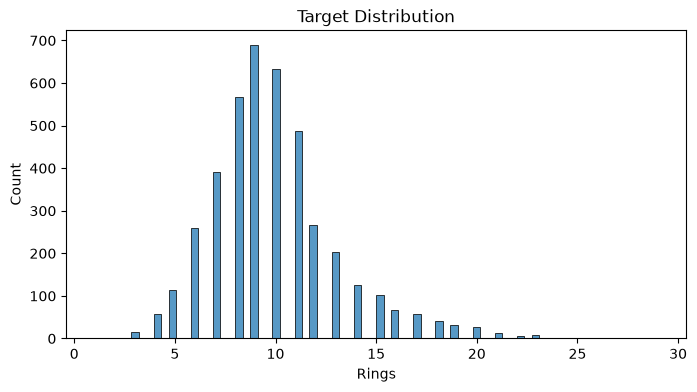

In [10]:
plt.figure(figsize = (8,4))

sns.histplot(abalone["rings"])

plt.xlabel("Rings")
plt.ylabel("Count")
plt.title("Target Distribution")
plt.show()

## 4. Defining the Features and Target

In [11]:
X = abalone.drop(columns="rings")
y = abalone["rings"]

In [12]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4177, 8)
y shape: (4177,)


## 5. Splitting the Features and Target

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

In [14]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(3341, 8)
(3341,)
(836, 8)
(836,)


## 6. EDA

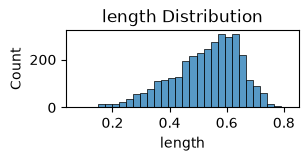

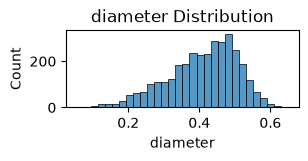

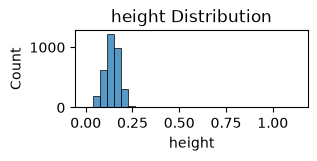

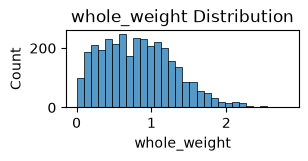

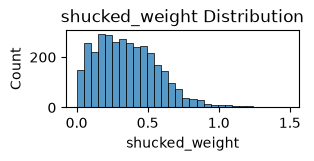

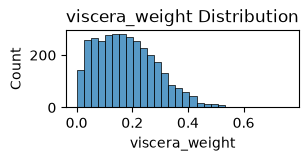

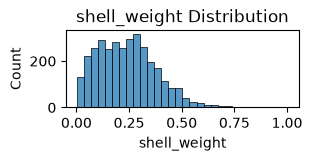

In [15]:
# Check Distribution of numerical features in X_train
numerical_columns = X_train.select_dtypes(include="number")

for col in numerical_columns:
    plt.figure(figsize=(3,1))

    sns.histplot(data= X_train, x=col, bins=30)
    plt.title(f"{col} Distribution")
    plt.xlabel(col)
    plt.ylabel("Count")

    plt.show()


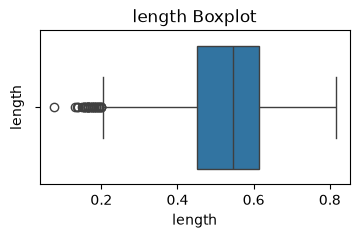

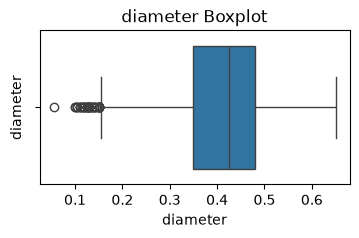

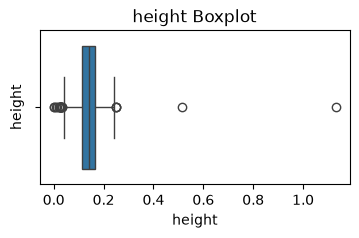

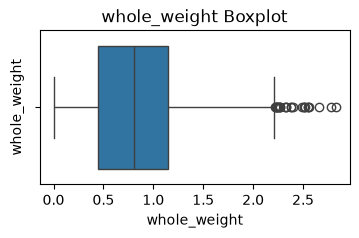

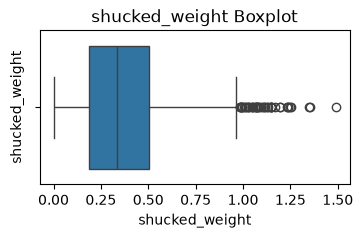

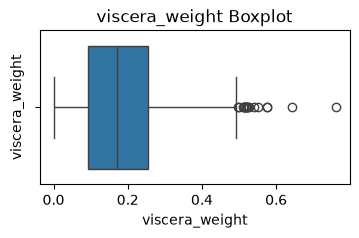

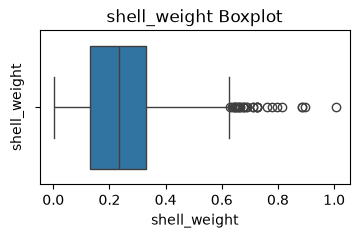

In [16]:
# Boxplot to check for outliers

for col in numerical_columns:

    plt.figure(figsize=(4,2))

    sns.boxplot(data=X_train, x=col)
    plt.title(f"{col} Boxplot")
    plt.ylabel(col)
    plt.show()

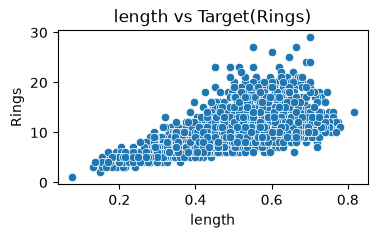

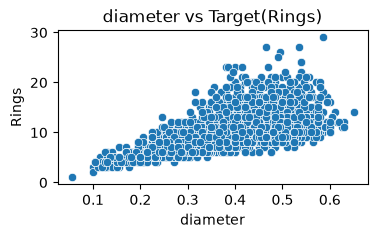

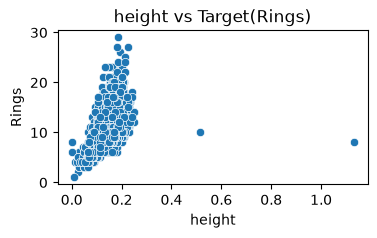

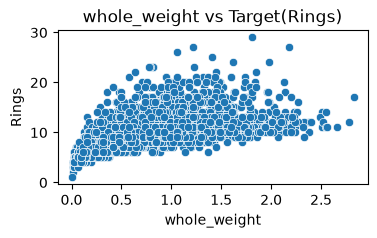

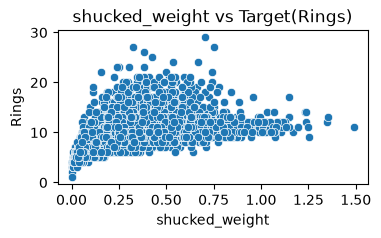

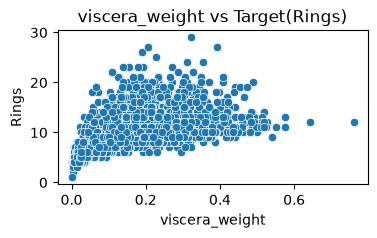

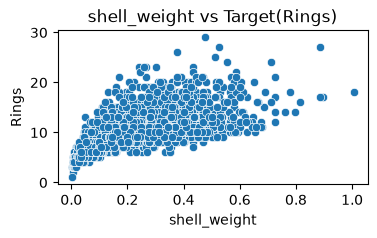

In [22]:
# Checking relationship between features and target using scatter plot
for col in numerical_columns:
    plt.figure(figsize=(4,2))

    sns.scatterplot(data=X_train, x=col, y=y_train)
    plt.title(f"{col} vs Target(Rings)")
    plt.xlabel(col)
    plt.ylabel("Rings")

    plt.show()

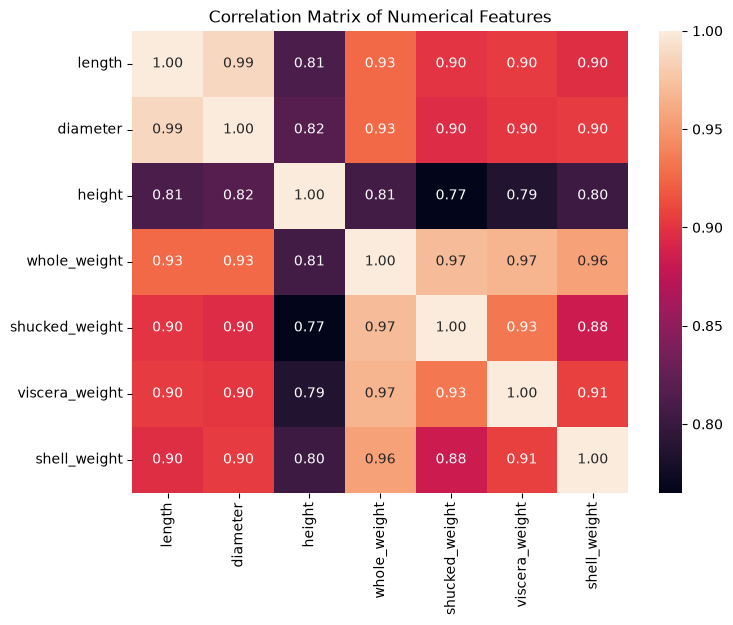

In [23]:
# Correlation Between numerical features
correlation_matrix = X_train[numerical_columns.columns].corr()

plt.figure(figsize=(8,6))
sns.heatmap(data=correlation_matrix, annot=True, fmt=".2f")
plt.title("Correlation Matrix of Numerical Features")
plt.show()